# Cache-Aware Structured Pruning with Built-in ViT-B/16 on CIFAR-100

This notebook uses the **official `torchvision.models.vit_b_16` implementation** with ImageNet pretrained weights, fine-tunes it for CIFAR-100, physically compacts attention heads and MLP hidden units, then compares baseline, conventional compact pruning, and cache-aware compact pruning.

**Important research notes**
- Default `SMOKE_TEST=True` is for pipeline validation, not final scientific results. Set it to `False` for longer training.
- Cache estimates are analytical proxies, not measured hardware cache counters. Use NVIDIA Nsight Compute for hardware-level cache metrics.
- Energy from NVML power × elapsed time is approximate. Run multiple trials and report mean ± standard deviation.
- Cache benefit is modeled at the layer level. The global selection across candidates allows layer-specific cache effects to influence pruning allocation; it does not claim that every head within one layer has a distinct cache footprint.
- Pretrained weights are downloaded by torchvision on first use. CIFAR images are resized to 224×224 for ViT-B/16.

## 1. Install dependencies (run once if needed)

If your environment already has compatible PyTorch and torchvision installed, skip this cell. Restart the kernel if package installation upgrades either package.

In [1]:
# Uncomment if needed, then restart the kernel:
# %pip install -U torch torchvision pandas matplotlib tqdm
# Optional for GPU power/energy measurement:
# %pip install nvidia-ml-py

## 2. Configuration

In [2]:
import os, copy, time, math, random, warnings, json, platform
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
from torchvision import datasets
from torchvision.models import vit_b_16, ViT_B_16_Weights
from torch.utils.data import DataLoader, random_split
from tqdm.auto import tqdm

SEED = 42
DATA_DIR = "./data"
OUTPUT_DIR = Path("./vit_pruning_results")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Quick pipeline test. Set False for final experiments.
SMOKE_TEST = False
NUM_WORKERS = 0  # robust default for notebook/Windows/Python multiprocessing issues
BATCH_SIZE = 16
EVAL_BATCH_SIZE = 16
VAL_FRACTION = 0.10

BASELINE_EPOCHS = 2 if SMOKE_TEST else 20
FINETUNE_EPOCHS = 1 if SMOKE_TEST else 8
ENERGY_BATCHES = 10 if SMOKE_TEST else 100
MAX_TRAIN_BATCHES = 20 if SMOKE_TEST else None
MAX_EVAL_BATCHES = 10 if SMOKE_TEST else None

LEARNING_RATE = 2e-5
HEAD_LR = 2e-4
WEIGHT_DECAY = 0.05
PRUNE_RATIO = 0.20  # fraction of attention heads / MLP units considered for removal, per layer
CACHE_BUDGET_MB = 4.0
ALPHA = 1.0
BETA = 0.15
GAMMA = 0.05

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Python:", platform.python_version())
print("PyTorch:", torch.__version__, "| torchvision:", torchvision.__version__)
print("Device:", DEVICE)
if DEVICE.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

/home/komal-sai-jakka/PythonEnvs/ml_env/lib/python3.14/site-packages/torch/cuda/__init__.py:63: FutureWarning: The pynvml package is deprecated. Please install nvidia-ml-py instead. If you did not install pynvml directly, please report this to the maintainers of the package that installed pynvml for you.
  import pynvml  # type: ignore[import]


Python: 3.14.4
PyTorch: 2.12.1+cu130 | torchvision: 0.27.1+cu130
Device: cuda
GPU: NVIDIA GeForce RTX 4050 Laptop GPU


## 3. Reproducibility and data

In [3]:
def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed()

weights = ViT_B_16_Weights.DEFAULT
image_transform = weights.transforms()

train_full = datasets.CIFAR100(
    root=DATA_DIR, train=True, download=True, transform=image_transform
)
test_dataset = datasets.CIFAR100(
    root=DATA_DIR, train=False, download=True, transform=image_transform
)

val_size = int(len(train_full) * VAL_FRACTION)
train_size = len(train_full) - val_size
split_generator = torch.Generator().manual_seed(SEED)
train_dataset, val_dataset = random_split(
    train_full, [train_size, val_size], generator=split_generator
)

train_loader = DataLoader(
    train_dataset, batch_size=BATCH_SIZE, shuffle=True,
    num_workers=NUM_WORKERS, pin_memory=(DEVICE.type == "cuda")
)
val_loader = DataLoader(
    val_dataset, batch_size=EVAL_BATCH_SIZE, shuffle=False,
    num_workers=NUM_WORKERS, pin_memory=(DEVICE.type == "cuda")
)
test_loader = DataLoader(
    test_dataset, batch_size=EVAL_BATCH_SIZE, shuffle=False,
    num_workers=NUM_WORKERS, pin_memory=(DEVICE.type == "cuda")
)

print(f"Train={len(train_dataset):,}; validation={len(val_dataset):,}; test={len(test_dataset):,}")
print("Input transform:", image_transform)

Train=45,000; validation=5,000; test=10,000
Input transform: ImageClassification(
    crop_size=[224]
    resize_size=[256]
    mean=[0.485, 0.456, 0.406]
    std=[0.229, 0.224, 0.225]
    interpolation=InterpolationMode.BILINEAR
)


## 4. Build the built-in ViT-B/16 and training utilities

In [4]:
def build_pretrained_vit(num_classes=100):
    model = vit_b_16(weights=ViT_B_16_Weights.DEFAULT)
    in_features = model.heads.head.in_features
    model.heads.head = nn.Linear(in_features, num_classes)
    return model

def count_parameters(model, trainable_only=False):
    return sum(p.numel() for p in model.parameters()
               if (p.requires_grad or not trainable_only))

@torch.no_grad()
def evaluate(model, loader, max_batches=None):
    model.eval()
    loss_sum, correct, total = 0.0, 0, 0
    criterion = nn.CrossEntropyLoss()
    for batch_idx, (images, labels) in enumerate(loader):
        if max_batches is not None and batch_idx >= max_batches:
            break
        images, labels = images.to(DEVICE), labels.to(DEVICE)
        logits = model(images)
        loss = criterion(logits, labels)
        loss_sum += loss.item() * labels.size(0)
        correct += (logits.argmax(1) == labels).sum().item()
        total += labels.size(0)
    return {"loss": loss_sum / max(total, 1), "accuracy": correct / max(total, 1), "n": total}

def train_model(model, loader, epochs, lr=LEARNING_RATE, max_batches=None, desc="train"):
    model.to(DEVICE)
    criterion = nn.CrossEntropyLoss(label_smoothing=0.1)
    optimizer = torch.optim.AdamW(
        [
            {"params": [p for n,p in model.named_parameters() if not n.startswith("heads.")], "lr": lr},
            {"params": model.heads.parameters(), "lr": HEAD_LR},
        ],
        weight_decay=WEIGHT_DECAY,
    )
    history = []
    for epoch in range(epochs):
        model.train()
        running_loss, correct, total = 0.0, 0, 0
        start = time.perf_counter()
        iterator = tqdm(enumerate(loader), total=(min(len(loader), max_batches) if max_batches else len(loader)),
                       desc=f"{desc} {epoch+1}/{epochs}", leave=False)
        for batch_idx, (images, labels) in iterator:
            if max_batches is not None and batch_idx >= max_batches:
                break
            images, labels = images.to(DEVICE), labels.to(DEVICE)
            optimizer.zero_grad(set_to_none=True)
            logits = model(images)
            loss = criterion(logits, labels)
            loss.backward()
            optimizer.step()
            running_loss += loss.item() * labels.size(0)
            correct += (logits.argmax(1) == labels).sum().item()
            total += labels.size(0)
            iterator.set_postfix(loss=f"{loss.item():.3f}")
        val = evaluate(model, val_loader, MAX_EVAL_BATCHES)
        history.append({
            "epoch": epoch+1, "train_loss": running_loss/max(total,1),
            "train_accuracy": correct/max(total,1), "val_loss": val["loss"],
            "val_accuracy": val["accuracy"], "epoch_seconds": time.perf_counter()-start
        })
        print(f"{desc} epoch {epoch+1}: train_acc={correct/max(total,1):.4f}, val_acc={val['accuracy']:.4f}")
    return pd.DataFrame(history)

## 5. Train or fine-tune the baseline

In [5]:
baseline = build_pretrained_vit()
print(f"Baseline parameters: {count_parameters(baseline):,}")
baseline_history = train_model(
    baseline, train_loader, BASELINE_EPOCHS,
    max_batches=MAX_TRAIN_BATCHES, desc="baseline"
)
baseline_history.to_csv(OUTPUT_DIR / "baseline_training_history.csv", index=False)

baseline_val = evaluate(baseline, val_loader, MAX_EVAL_BATCHES)
baseline_test = evaluate(baseline, test_loader, MAX_EVAL_BATCHES)
print("Baseline validation:", baseline_val)
print("Baseline test:", baseline_test)

torch.save(baseline.state_dict(), OUTPUT_DIR / "baseline_vit_b16_cifar100.pt")

Baseline parameters: 85,875,556


baseline 1/20:   0%|          | 0/2813 [00:00<?, ?it/s]

baseline epoch 1: train_acc=0.7786, val_acc=0.8508


baseline 2/20:   0%|          | 0/2813 [00:00<?, ?it/s]

baseline epoch 2: train_acc=0.9064, val_acc=0.8612


baseline 3/20:   0%|          | 0/2813 [00:00<?, ?it/s]

... (31 outputs left out)

baseline 19/20:   0%|          | 0/2813 [00:00<?, ?it/s]

baseline epoch 19: train_acc=0.9919, val_acc=0.8382


baseline 20/20:   0%|          | 0/2813 [00:00<?, ?it/s]

baseline epoch 20: train_acc=0.9913, val_acc=0.8538
Baseline validation: {'loss': 0.7357321046590805, 'accuracy': 0.8538, 'n': 5000}
Baseline test: {'loss': 0.7050264861106873, 'accuracy': 0.8559, 'n': 10000}


## 6. Candidate importance and analytical cache proxy

For each encoder block:
- attention head importance is estimated from the magnitude of that head's Q/K/V projection weights;
- MLP-unit importance is estimated from the incoming `mlp.0` row and outgoing `mlp.3` column magnitudes;
- the analytical working-set proxy includes attention projection weights, MLP weights, and token activations.

The cache-aware policy selects globally across all eligible head/unit candidates under a matched total pruning budget. Candidate cache benefit is based on the *marginal layer-level working-set reduction*; within a layer, that benefit is shared by candidates because the standard dense ViT structure gives heads/units equal dimensions. This is intentional and avoids pretending there are per-head cache measurements.

In [6]:
def block_working_set_bytes(block, batch_size=1, seq_len=197, dtype_bytes=4):
    # Analytical proxy only: parameters/activations touched in one encoder block.
    attn = block.self_attention
    d = attn.embed_dim
    h = attn.num_heads
    head_dim = d // h
    mlp_in = block.mlp[0].in_features
    mlp_out = block.mlp[0].out_features
    weight_params = (
        3*d*d + d*d + d*mlp_out + mlp_out*d
    )
    activation_elements = batch_size * seq_len * (4*d + 2*mlp_out)
    return int(weight_params * dtype_bytes + activation_elements * dtype_bytes)

def collect_candidates(model):
    rows = []
    blocks = model.encoder.layers
    for layer_idx, block in enumerate(blocks):
        attn = block.self_attention
        d, h = attn.embed_dim, attn.num_heads
        hd = d // h
        qkv = attn.in_proj_weight.detach().abs()
        qkv_bias = attn.in_proj_bias.detach().abs() if attn.in_proj_bias is not None else None
        out_w = attn.out_proj.weight.detach().abs()
        for head in range(h):
            idx = torch.arange(head*hd, (head+1)*hd, device=qkv.device)
            # Q, K, V each use a separate d-row segment in in_proj_weight.
            importance = qkv[idx].mean() + qkv[d+idx].mean() + qkv[2*d+idx].mean()
            importance += out_w[:, idx].mean()
            if qkv_bias is not None:
                importance += qkv_bias[idx].mean() + qkv_bias[d+idx].mean() + qkv_bias[2*d+idx].mean()
            rows.append({
                "kind": "head", "layer": layer_idx, "unit": head,
                "importance": float(importance.item()),
                "cost": float(4 * d * hd),
                "working_set_bytes": block_working_set_bytes(block),
            })
        fc1, fc2 = block.mlp[0], block.mlp[3]
        for unit in range(fc1.out_features):
            importance = fc1.weight[unit].detach().abs().mean() + fc2.weight[:, unit].detach().abs().mean()
            if fc1.bias is not None:
                importance += fc1.bias[unit].detach().abs()
            rows.append({
                "kind": "mlp", "layer": layer_idx, "unit": unit,
                "importance": float(importance.item()),
                "cost": float(fc1.in_features + fc2.out_features),
                "working_set_bytes": block_working_set_bytes(block),
            })
    return pd.DataFrame(rows)

candidates = collect_candidates(baseline)
print(candidates.groupby("kind").size())
candidates.head()

kind
head      144
mlp     36864
dtype: int64


,kind,layer,unit,importance,cost,working_set_bytes
0,head,0,0,0.206098,196608.0,35573760
1,head,0,1,0.274135,196608.0,35573760
2,head,0,2,0.112292,196608.0,35573760
3,head,0,3,0.189811,196608.0,35573760
4,head,0,4,0.126920,196608.0,35573760


## 7. Choose matched pruning candidates: conventional vs cache-aware

In [7]:
def choose_candidates(candidate_df, policy, prune_ratio=PRUNE_RATIO):
    df = candidate_df.copy()
    # Separate structure types to avoid mixing heads and MLP units in one budget.
    chosen = []
    for kind, group in df.groupby("kind"):
        n_remove = max(1, int(round(len(group) * prune_ratio)))
        g = group.copy()
        # Normalize importance globally within each candidate type.
        imp = (g["importance"] - g["importance"].min()) / (g["importance"].max() - g["importance"].min() + 1e-12)
        # Estimated layer-level cache benefit: reduce penalty if a layer's estimated
        # working set exceeds budget. It is shared by candidates in the same layer.
        ws_mb = g["working_set_bytes"] / (1024**2)
        cache_penalty = np.maximum(ws_mb - CACHE_BUDGET_MB, 0.0)
        layer_cache_benefit = cache_penalty / (ws_mb + 1e-12)
        # Candidate marginal cost uses its own structure size, normalized.
        cost = (g["cost"] - g["cost"].min()) / (g["cost"].max() - g["cost"].min() + 1e-12)
        if policy == "conventional":
            g["score"] = imp
        elif policy == "cache_aware":
            # Lower score is preferred for pruning. Cache benefit reduces score,
            # while removal cost increases it. Importance increases score.
            g["score"] = ALPHA * imp - BETA * layer_cache_benefit + GAMMA * cost
        else:
            raise ValueError(policy)
        # To make layer-specific cache effects influence allocation, rank candidates
        # globally across layers (not a fixed quota per layer).
        chosen.append(g.nsmallest(n_remove, "score"))
    return pd.concat(chosen, ignore_index=True)

conventional_candidates = choose_candidates(candidates, "conventional")
cache_candidates = choose_candidates(candidates, "cache_aware")
print("Conventional removals:", conventional_candidates.groupby("kind").size().to_dict())
print("Cache-aware removals:", cache_candidates.groupby("kind").size().to_dict())
print("Overlap:", len(set(zip(conventional_candidates.kind, conventional_candidates.layer, conventional_candidates.unit)) &
                        set(zip(cache_candidates.kind, cache_candidates.layer, cache_candidates.unit))))

Conventional removals: {'head': 29, 'mlp': 7373}
Cache-aware removals: {'head': 29, 'mlp': 7373}
Overlap: 7402


## 8. Physically compact ViT-B/16

This rebuilds each block with fewer attention heads and fewer MLP hidden units, slicing the pretrained tensors into smaller dense layers. It is not just masking: matrix dimensions and parameter count change.

**Implementation limitation:** PyTorch's stock `nn.MultiheadAttention` requires the same embedding dimension for its input/output and has fixed head dimension tied to `embed_dim // num_heads`. Removing heads while preserving the model's residual embedding dimension therefore needs a custom compact attention module. This notebook uses a custom attention implementation inside the torchvision encoder block structure while retaining the built-in model's patch embedding, class token, positional embedding, layer norms, and classifier.

In [8]:
class CompactSelfAttention(nn.Module):
    def __init__(self, embed_dim, head_dim, num_heads, qkv_weight, qkv_bias, out_weight, out_bias):
        super().__init__()
        self.embed_dim = embed_dim
        self.head_dim = head_dim
        self.num_heads = num_heads
        self.inner_dim = head_dim * num_heads
        self.qkv = nn.Linear(embed_dim, 3*self.inner_dim, bias=qkv_bias is not None)
        self.proj = nn.Linear(self.inner_dim, embed_dim, bias=out_bias is not None)
        with torch.no_grad():
            d = embed_dim
            kept = []
            # qkv_weight uses [Q rows 0:d, K rows d:2d, V rows 2d:3d]
            # qkv rows selected per retained original head.
            for section in range(3):
                for h in range(qkv_weight.shape[0] // 3 // head_dim):
                    pass
            # qkv_weight is source in_proj_weight; head indices supplied later
        self._initialize_from_source(qkv_weight, qkv_bias, out_weight, out_bias, None)

    def _initialize_from_source(self, *args):
        # Populated by the factory function below.
        return

    def forward(self, x):
        b, n, _ = x.shape
        qkv = self.qkv(x).reshape(b, n, 3, self.num_heads, self.head_dim).permute(2,0,3,1,4)
        q, k, v = qkv[0], qkv[1], qkv[2]
        y = F.scaled_dot_product_attention(q, k, v)
        y = y.transpose(1,2).reshape(b,n,self.inner_dim)
        return self.proj(y)

class CompactEncoderBlock(nn.Module):
    def __init__(self, source_block, kept_heads, kept_mlp_units):
        super().__init__()
        self.num_heads = len(kept_heads)
        self.embed_dim = source_block.ln_1.normalized_shape[0]
        self.head_dim = self.embed_dim // source_block.self_attention.num_heads
        self.ln_1 = copy.deepcopy(source_block.ln_1)
        self.ln_2 = copy.deepcopy(source_block.ln_2)

        src_attn = source_block.self_attention
        d = self.embed_dim
        hd = d // src_attn.num_heads
        row_idx = torch.tensor(
            [section*d + h*hd + j for section in range(3) for h in kept_heads for j in range(hd)],
            dtype=torch.long, device=src_attn.in_proj_weight.device
        )
        col_idx = torch.tensor([h*hd+j for h in kept_heads for j in range(hd)],
                               dtype=torch.long, device=src_attn.in_proj_weight.device)
        inner = len(kept_heads)*hd
        self.self_attention = nn.Module()
        self.self_attention.qkv = nn.Linear(d, 3*inner, bias=src_attn.in_proj_bias is not None)
        self.self_attention.proj = nn.Linear(inner, d, bias=src_attn.out_proj.bias is not None)
        with torch.no_grad():
            self.self_attention.qkv.weight.copy_(src_attn.in_proj_weight[row_idx])
            if src_attn.in_proj_bias is not None:
                self.self_attention.qkv.bias.copy_(src_attn.in_proj_bias[row_idx])
            self.self_attention.proj.weight.copy_(src_attn.out_proj.weight[:, col_idx])
            if src_attn.out_proj.bias is not None:
                self.self_attention.proj.bias.copy_(src_attn.out_proj.bias)

        fc1, fc2 = source_block.mlp[0], source_block.mlp[3]
        unit_idx = torch.tensor(kept_mlp_units, dtype=torch.long, device=fc1.weight.device)
        self.mlp = nn.Sequential(
            nn.Linear(fc1.in_features, len(kept_mlp_units), bias=fc1.bias is not None),
            copy.deepcopy(source_block.mlp[1]),
            nn.Dropout(source_block.mlp[2].p),
            nn.Linear(len(kept_mlp_units), fc2.out_features, bias=fc2.bias is not None),
            copy.deepcopy(source_block.mlp[4]),
        )
        with torch.no_grad():
            self.mlp[0].weight.copy_(fc1.weight[unit_idx])
            if fc1.bias is not None:
                self.mlp[0].bias.copy_(fc1.bias[unit_idx])
            self.mlp[3].weight.copy_(fc2.weight[:, unit_idx])
            if fc2.bias is not None:
                self.mlp[3].bias.copy_(fc2.bias)

    def forward(self, x):
        x = x + self.self_attention.proj(
            self._attention(self.self_attention.qkv(self.ln_1(x)))
        )
        x = x + self.mlp(self.ln_2(x))
        return x

    def _attention(self, qkv):
        b, n, _ = qkv.shape
        inner = qkv.shape[-1] // 3
        qkv = qkv.reshape(b, n, 3, self.num_heads, self.head_dim).permute(2,0,3,1,4)
        q, k, v = qkv[0], qkv[1], qkv[2]
        out = F.scaled_dot_product_attention(q, k, v)
        return out.transpose(1,2).reshape(b,n,inner)

def build_compact_model(source_model, removed_df):
    compact = copy.deepcopy(source_model)
    new_layers = []
    removed_keys = set(zip(removed_df["kind"], removed_df["layer"], removed_df["unit"]))
    for li, block in enumerate(source_model.encoder.layers):
        n_heads = block.self_attention.num_heads
        n_mlp = block.mlp[0].out_features
        removed_heads = {u for kind, layer, u in removed_keys if kind == "head" and layer == li}
        removed_units = {u for kind, layer, u in removed_keys if kind == "mlp" and layer == li}
        kept_heads = [h for h in range(n_heads) if h not in removed_heads]
        kept_units = [u for u in range(n_mlp) if u not in removed_units]
        if not kept_heads:
            kept_heads = [0]
        if not kept_units:
            kept_units = [0]
        new_layers.append(CompactEncoderBlock(block, kept_heads, kept_units))
    compact.encoder.layers = nn.Sequential(*new_layers)
    return compact

conventional_model = build_compact_model(
    baseline, conventional_candidates
).to(DEVICE)

cache_model = build_compact_model(
    baseline, cache_candidates
).to(DEVICE)

print("Baseline params:", count_parameters(baseline))
print("Conventional compact params:", count_parameters(conventional_model))
print("Cache-aware compact params:", count_parameters(cache_model))

assert count_parameters(conventional_model) < count_parameters(baseline)
assert count_parameters(cache_model) < count_parameters(baseline)

# Forward-pass sanity check
sample_images, _ = next(iter(val_loader))

conventional_model.eval()
with torch.no_grad():
    logits = conventional_model(sample_images[:2].to(DEVICE))

print("Sanity-check logits shape:", tuple(logits.shape))

Baseline params: 85875556
Conventional compact params: 68836055
Cache-aware compact params: 68836055
Sanity-check logits shape: (2, 100)


## 9. Fine-tune compact models and evaluate

In [9]:
conv_history = train_model(
    conventional_model, train_loader, FINETUNE_EPOCHS,
    lr=LEARNING_RATE, max_batches=MAX_TRAIN_BATCHES, desc="conventional fine-tune"
)
cache_history = train_model(
    cache_model, train_loader, FINETUNE_EPOCHS,
    lr=LEARNING_RATE, max_batches=MAX_TRAIN_BATCHES, desc="cache-aware fine-tune"
)
conv_history.to_csv(OUTPUT_DIR / "conventional_finetune_history.csv", index=False)
cache_history.to_csv(OUTPUT_DIR / "cache_aware_finetune_history.csv", index=False)

val_conv = evaluate(conventional_model, val_loader, MAX_EVAL_BATCHES)
test_conv = evaluate(conventional_model, test_loader, MAX_EVAL_BATCHES)
val_cache = evaluate(cache_model, val_loader, MAX_EVAL_BATCHES)
test_cache = evaluate(cache_model, test_loader, MAX_EVAL_BATCHES)
print("Conventional validation/test:", val_conv, test_conv)
print("Cache-aware validation/test:", val_cache, test_cache)

torch.save(conventional_model.state_dict(), OUTPUT_DIR / "conventional_compact_vit_b16.pt")
torch.save(cache_model.state_dict(), OUTPUT_DIR / "cache_aware_compact_vit_b16.pt")

conventional fine-tune 1/8:   0%|          | 0/2813 [00:00<?, ?it/s]

conventional fine-tune epoch 1: train_acc=0.9448, val_acc=0.8326


conventional fine-tune 2/8:   0%|          | 0/2813 [00:00<?, ?it/s]

conventional fine-tune epoch 2: train_acc=0.9780, val_acc=0.8270


conventional fine-tune 3/8:   0%|          | 0/2813 [00:00<?, ?it/s]

conventional fine-tune epoch 3: train_acc=0.9817, val_acc=0.8298


... (22 outputs left out)

cache-aware fine-tune 7/8:   0%|          | 0/2813 [00:00<?, ?it/s]

cache-aware fine-tune epoch 7: train_acc=0.9876, val_acc=0.8164


cache-aware fine-tune 8/8:   0%|          | 0/2813 [00:00<?, ?it/s]

cache-aware fine-tune epoch 8: train_acc=0.9894, val_acc=0.8272
Conventional validation/test: {'loss': 0.7969786788344383, 'accuracy': 0.8358, 'n': 5000} {'loss': 0.82013605209589, 'accuracy': 0.8296, 'n': 10000}
Cache-aware validation/test: {'loss': 0.8335739503622055, 'accuracy': 0.8272, 'n': 5000} {'loss': 0.8433008155822754, 'accuracy': 0.8282, 'n': 10000}


## 10. Latency, throughput, GPU memory, power, and approximate energy

In [10]:
def try_nvml():
    try:
        import pynvml
        pynvml.nvmlInit()
        handle = pynvml.nvmlDeviceGetHandleByIndex(torch.cuda.current_device() if DEVICE.type == "cuda" else 0)
        return pynvml, handle
    except Exception as e:
        print("NVML unavailable; power/energy will be NaN:", repr(e))
        return None, None

pynvml_mod, nvml_handle = try_nvml()

def gpu_power_watts():
    if pynvml_mod is None or DEVICE.type != "cuda":
        return float("nan")
    try:
        return pynvml_mod.nvmlDeviceGetPowerUsage(nvml_handle) / 1000.0
    except Exception:
        return float("nan")

@torch.no_grad()
def benchmark(model, loader, max_batches=ENERGY_BATCHES, warmup_batches=3):
    model.eval().to(DEVICE)
    iterator = iter(loader)
    for _ in range(warmup_batches):
        try:
            x, _ = next(iterator)
        except StopIteration:
            break
        model(x.to(DEVICE))
    if DEVICE.type == "cuda":
        torch.cuda.synchronize()
        torch.cuda.reset_peak_memory_stats()

    elapsed_times, batch_sizes, powers = [], [], []
    energy_j = 0.0
    measured = 0
    iterator = iter(loader)
    for bi in range(max_batches):
        try:
            x, _ = next(iterator)
        except StopIteration:
            break
        x = x.to(DEVICE)
        if DEVICE.type == "cuda":
            torch.cuda.synchronize()
        t0 = time.perf_counter()
        model(x)
        if DEVICE.type == "cuda":
            torch.cuda.synchronize()
        dt = time.perf_counter() - t0
        p = gpu_power_watts()
        elapsed_times.append(dt)
        batch_sizes.append(x.size(0))
        powers.append(p)
        if np.isfinite(p):
            energy_j += p * dt
        measured += 1

    total_images = sum(batch_sizes)
    total_time = sum(elapsed_times)
    finite_power = np.array(powers, dtype=float)
    avg_power = float(np.nanmean(finite_power)) if np.isfinite(finite_power).any() else float("nan")
    peak_mem = torch.cuda.max_memory_allocated() / (1024**2) if DEVICE.type == "cuda" else float("nan")
    return {
        "Batch Latency Mean (s)": float(np.mean(elapsed_times)) if elapsed_times else float("nan"),
        "Batch Latency P50 (s)": float(np.percentile(elapsed_times, 50)) if elapsed_times else float("nan"),
        "Batch Latency P95 (s)": float(np.percentile(elapsed_times, 95)) if elapsed_times else float("nan"),
        "Images/s": total_images / total_time if total_time else float("nan"),
        "Peak GPU Memory (MB)": peak_mem,
        "Avg GPU Power (W)": avg_power,
        "Energy (J)": energy_j if np.isfinite(avg_power) else float("nan"),
        "Energy/Image (J)": energy_j / total_images if total_images and np.isfinite(avg_power) else float("nan"),
        "Measured batches": measured,
    }

benchmark_rows = []
for name, model, val, test in [
    ("Baseline", baseline, baseline_val, baseline_test),
    ("Conventional compact", conventional_model, val_conv, test_conv),
    ("Cache-aware compact", cache_model, val_cache, test_cache),
]:
    metrics = benchmark(model, test_loader)
    benchmark_rows.append({
        "Model": name,
        "Parameters": count_parameters(model),
        "Val Accuracy": val["accuracy"],
        "Test Accuracy": test["accuracy"],
        **metrics,
    })

results = pd.DataFrame(benchmark_rows)
baseline_energy = results.loc[results["Model"]=="Baseline", "Energy/Image (J)"].iloc[0]
results["Accuracy Change (pp)"] = (results["Test Accuracy"] - results.loc[results["Model"]=="Baseline", "Test Accuracy"].iloc[0]) * 100
results["Energy Reduction (%)"] = (1 - results["Energy/Image (J)"] / baseline_energy) * 100 if np.isfinite(baseline_energy) else np.nan
results.to_csv(OUTPUT_DIR / "final_comparison.csv", index=False)
results

,Model,Parameters,Val Accuracy,Test Accuracy,Batch Latency Mean (s),Batch Latency P50 (s),Batch Latency P95 (s),Images/s,Peak GPU Memory (MB),Avg GPU Power (W),Energy (J),Energy/Image (J),Measured batches,Accuracy Change (pp),Energy Reduction (%)
0,Baseline,85875556,0.8538,0.8559,0.102087,0.102086,0.104268,156.728845,1891.650879,76.54852,781.328546,0.488330,100,0.00,0.000000
1,Conventional compact,68836055,0.8358,0.8296,0.083283,0.083322,0.085519,192.117140,1891.555176,77.78000,647.780242,0.404863,100,-2.63,17.092464
2,Cache-aware compact,68836055,0.8272,0.8282,0.083567,0.083402,0.085670,191.463296,1891.555176,77.05270,643.921225,0.402451,100,-2.77,17.586369


## 11. Visualize and save comparisons

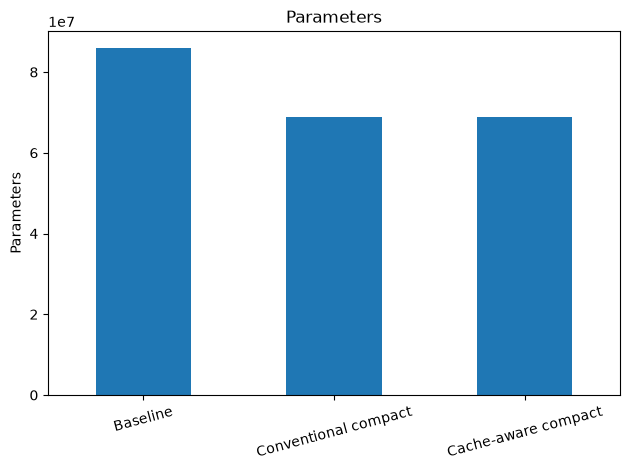

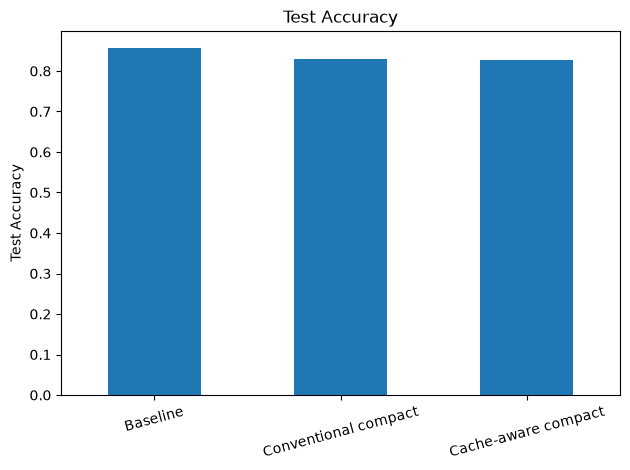

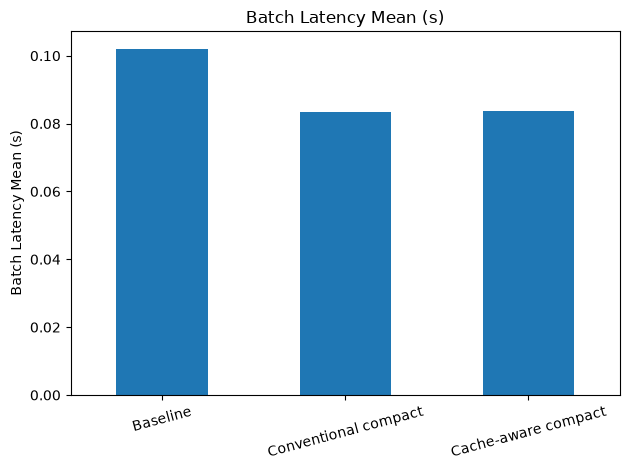

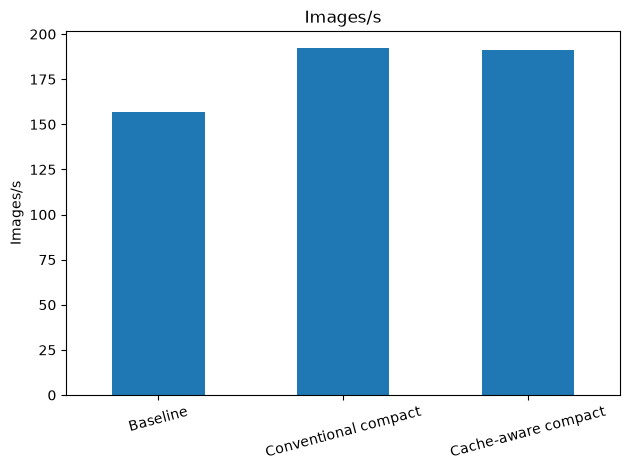

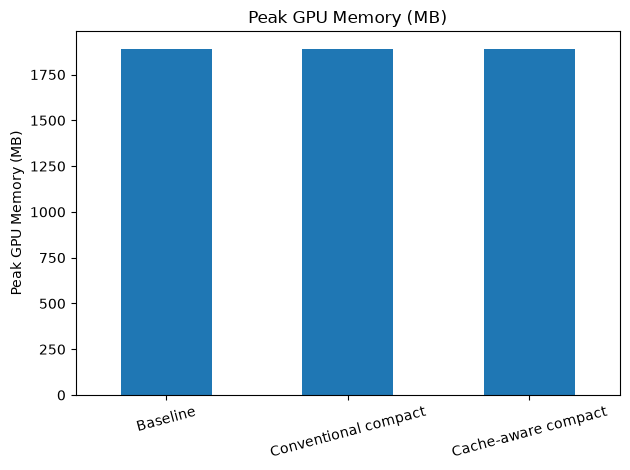

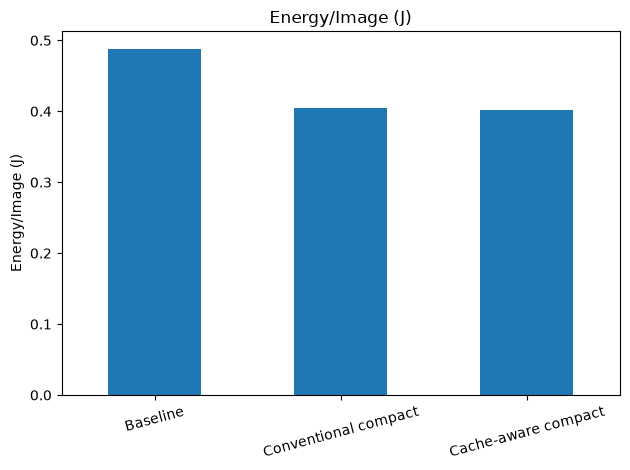

Results saved to: /home/komal-sai-jakka/ACADEMICS/5th_sem/machine_learning/research/VIT-TINY/vit_pruning_results
['baseline_training_history.csv', 'baseline_vit_b16_cifar100.pt', 'batch_latency_mean_(s).png', 'cache_aware_compact_vit_b16.pt', 'cache_aware_finetune_history.csv', 'conventional_compact_vit_b16.pt', 'conventional_finetune_history.csv', 'energy_image_(j).png', 'final_comparison.csv', 'images_s.png', 'parameters.png', 'peak_gpu_memory_(mb).png', 'test_accuracy.png']


In [11]:
def plot_metric(metric, ylabel=None, filename=None):
    ax = results.plot(x="Model", y=metric, kind="bar", legend=False, rot=15)
    ax.set_ylabel(ylabel or metric)
    ax.set_xlabel("")
    ax.set_title(metric)
    plt.tight_layout()
    if filename:
        plt.savefig(OUTPUT_DIR / filename, dpi=160, bbox_inches="tight")
    plt.show()

for metric in ["Parameters", "Test Accuracy", "Batch Latency Mean (s)", "Images/s", "Peak GPU Memory (MB)", "Energy/Image (J)"]:
    plot_metric(metric, filename=metric.lower().replace(" ", "_").replace("/", "_") + ".png")

print("Results saved to:", OUTPUT_DIR.resolve())
print(sorted(p.name for p in OUTPUT_DIR.iterdir()))

## 12. Research checklist before reporting results

1. Set `SMOKE_TEST = False`; train to convergence and save the exact config/checkpoint.
2. Run at least 3–5 random seeds and several benchmark repetitions. Report mean ± standard deviation.
3. Use the same pruning budget and fine-tuning schedule for conventional and cache-aware policies.
4. Report parameter count, latency, throughput, accuracy, peak memory, and energy per image.
5. State clearly that this cache model is an analytical proxy. For hardware cache claims, profile with NVIDIA Nsight Compute and report available L1/L2 hit rates, DRAM bytes, and kernel timings.
6. Do not use test accuracy to choose pruning hyperparameters; use validation data, and reserve test evaluation for final selected models.
7. Record GPU model, driver, CUDA/PyTorch/torchvision versions, power-measurement method, and batch size.